# Clasificación de planos anatómicos fetales — Benchmark de 3 modelos (versión limpia)

**Modelos:** EfficientNetV2-B0 · DenseNet-121 · Vision Transformer (ViT-B/16) · **XAI:** Grad-CAM, Score-CAM, Integrated Gradients (CNNs) y Attention Rollout (ViT).

**Cómo usarlo**
1. Entorno de ejecución → GPU (T4). Ejecuta las secciones **1 a 4** siempre (configuración, Drive, datos, pipeline).
2. Cada modelo (secciones 5, 6, 7) **carga el modelo guardado en Drive si existe**; si no existe, lo entrena y lo guarda. Para forzar un reentrenamiento pon `RETRAIN_* = True`.
3. La sección 8 arma la tabla comparativa y las figuras para las diapositivas (se guardan en `dataset/figuras`).

> Este notebook **no genera ni borra** imágenes en Drive salvo que no exista ninguna imagen `aug_*` (en ese caso las genera una sola vez).

## 1. Configuración del entorno

In [1]:
#@title 1. Imports, GPU y semillas
import os, re, sys, json, math, random, time, subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

# PyTorch + transformers (ViT) se importan ANTES que TensorFlow: evita un conflicto de librerías (LLVM/triton) entre ambos
import importlib.util
if importlib.util.find_spec('transformers') is None:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'transformers'], check=True)
import torch, torch._dynamo
from transformers import ViTModel

import tensorflow as tf
# IMPORTANTE: crecimiento de memoria ANTES de usar la GPU, para que PyTorch (ViT) también pueda usarla
gpus = tf.config.list_physical_devices('GPU')
for g in gpus:
    try: tf.config.experimental.set_memory_growth(g, True)
    except Exception as e: print('memory_growth:', e)

from tensorflow.keras import Input, Model, mixed_precision
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.applications import EfficientNetV2B0, DenseNet121
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils import class_weight

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
sns.set_theme(style='darkgrid')

IMG_SIZE   = 224
BATCH_SIZE = 64
WEIGHTS    = 'imagenet'

if gpus:
    mixed_precision.set_global_policy('mixed_float16')   # la T4 lo aprovecha muy bien
    print('GPU:', gpus[0].name, '| precisión mixta activada')
else:
    print('⚠️ NO HAY GPU. Ve a Entorno de ejecución > Cambiar tipo de entorno de ejecución > T4 GPU')
print('TensorFlow', tf.__version__)

GPU: /physical_device:GPU:0 | precisión mixta activada
TensorFlow 2.21.0


## 2. Drive y rutas

In [2]:
#@title 2. Montar Drive y localizar el dataset
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('(no es Colab: se omite el montaje de Drive)')

CANDIDATAS = [
    Path('/content/drive/MyDrive/Proyecto/dataset'),
    Path('/content/drive/MyDrive/IA2/Proyecto/dataset'),
    Path('/content/drive/MyDrive/dataset'),
    Path('/content/dataset'),   # dataset descargado con gdown (ver README, opcion B)
    # agrega aquí tu ruta si es otra
]
DATASET_DIR = next((p for p in CANDIDATAS if (p / 'fetal_planes_train.csv').exists()), None)
if DATASET_DIR is None:   # búsqueda de respaldo (1-2 niveles dentro de MyDrive)
    hallados = list(Path('/content/drive/MyDrive').glob('*/dataset/fetal_planes_train.csv')) + \
               list(Path('/content/drive/MyDrive').glob('*/*/dataset/fetal_planes_train.csv'))
    if hallados:
        DATASET_DIR = hallados[0].parent
if DATASET_DIR is None:
    raise FileNotFoundError('No encuentro fetal_planes_train.csv. Revisa que la carpeta dataset esté en tu Drive y agrégala a CANDIDATAS.')

if '.shortcut-targets-by-id' in str(DATASET_DIR.resolve()):
    print('⚠️ Estás usando la carpeta COMPARTIDA (acceso directo). Lo recomendable es trabajar sobre una copia en tu propio Drive.')

CSV_PATH_train = DATASET_DIR / 'fetal_planes_train.csv'
CSV_PATH_test  = DATASET_DIR / 'fetal_planes_test.csv'
image_dir      = DATASET_DIR / 'Images'
FIGS_DIR       = DATASET_DIR / 'figuras'; FIGS_DIR.mkdir(exist_ok=True)
META_PATH      = DATASET_DIR / 'benchmark_meta.json'   # tiempos y curvas de pérdida de cada entrenamiento

assert image_dir.exists(), f'No existe {image_dir}'
print('Dataset:', DATASET_DIR)

def find_file(name):
    """Busca un archivo (modelo, etc.) en las ubicaciones habituales del proyecto."""
    for d in [DATASET_DIR, DATASET_DIR / 'modelos', DATASET_DIR.parent / 'modelos', DATASET_DIR.parent]:
        if (d / name).exists():
            return d / name
    return None

def load_meta():
    return json.loads(META_PATH.read_text()) if META_PATH.exists() else {}
def save_meta(meta):
    META_PATH.write_text(json.dumps(meta, indent=1))

Mounted at /content/drive
⚠️ Estás usando la carpeta COMPARTIDA (acceso directo). Lo recomendable es trabajar sobre una copia en tu propio Drive.
Dataset: /content/drive/MyDrive/IA2/Proyecto/dataset


## 3. Datos: originales + aumentadas + test

Archivos en Images: 16638
Imágenes aug_* reconocidas: 4238

Train total: 12912 (originales 8674 + aumentadas 4238)
  -> entrenamiento: 10391 | validación: 1682 | test: 2169
Clases: ['Fetal abdomen', 'Fetal brain', 'Fetal femur', 'Fetal thorax', 'Maternal cervix', 'Other']
Pacientes de test que también aparecen en train: 862 de 1004


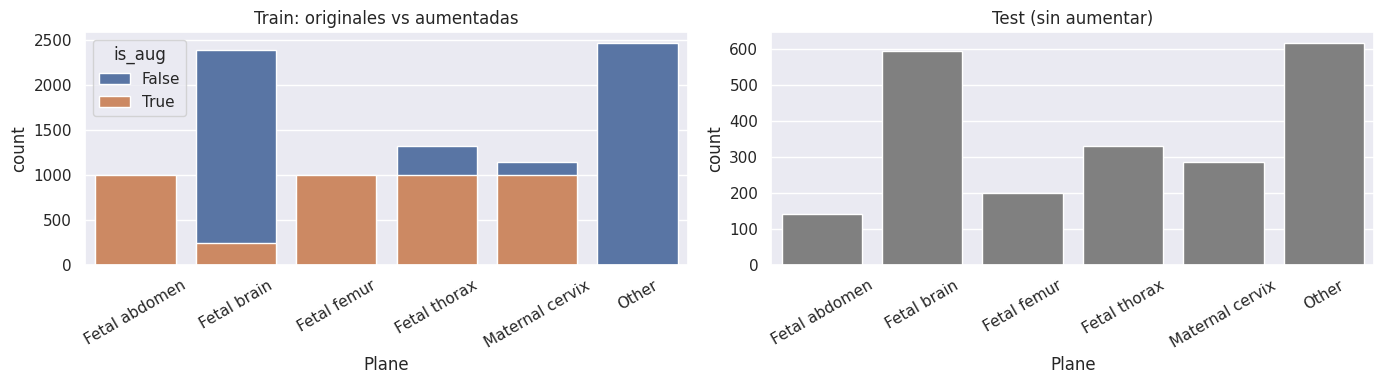

In [3]:
#@title 3. Preparar datos (sin borrar nada en Drive)
# Reglas:
#  - Se parte SIEMPRE del CSV original de train (no de un CSV aumentado de otra persona).
#  - Las imágenes aumentadas se reconstruyen desde los archivos aug_* que EXISTEN en Images,
#    así el listado nunca apunta a archivos inexistentes.
#  - Solo si no hay ninguna aug_* y GENERAR_AUG_SI_FALTAN=True, se generan (una vez).
GENERAR_AUG_SI_FALTAN = True
MAX_AUG_PER_CLASS = 1000

def patient_of(p):
    m = re.search(r'(Patient\d+)', Path(str(p)).name)
    return m.group(1) if m else Path(str(p)).name

existentes = {p.name for p in image_dir.iterdir()}        # un solo listado de Drive (rápido)
print('Archivos en Images:', len(existentes))

# --- originales de train ---
df_orig = pd.read_csv(CSV_PATH_train, sep=';')
df_orig['fname'] = df_orig['filepath'].map(lambda x: Path(str(x)).name)
df_orig = df_orig[~df_orig['fname'].str.startswith('aug_')].drop_duplicates('fname').reset_index(drop=True)
falt = ~df_orig['fname'].isin(existentes)
if falt.any():
    print(f'⚠️ {falt.sum()} imágenes originales de train no existen en Images y se descartan')
    df_orig = df_orig[~falt].reset_index(drop=True)
df_orig['filepath'] = df_orig['fname'].map(lambda n: image_dir / n)

# --- aumentadas existentes ---
plane_de = dict(zip(df_orig['fname'], df_orig['Plane']))
patron = re.compile(r'^aug_(.+?)_(\d+)_(Patient.*)$')
filas = []
for name in sorted(existentes):
    if name.startswith('aug_'):
        m = patron.match(name)
        if m and m.group(3) in plane_de:
            filas.append({'filepath': image_dir / name, 'Plane': plane_de[m.group(3)]})
df_aug = pd.DataFrame(filas, columns=['filepath', 'Plane'])
print('Imágenes aug_* reconocidas:', len(df_aug))

def augment_image(image_path):
    """Volteo horizontal aleatorio + rotación ±15° + brillo/contraste (OpenCV)."""
    img = cv2.imread(str(image_path))
    if img is None: return None
    if random.random() > 0.5: img = cv2.flip(img, 1)
    h, w = img.shape[:2]
    M = cv2.getRotationMatrix2D((w/2, h/2), random.randint(-15, 15), 1.0)
    img = cv2.warpAffine(img, M, (w, h), borderMode=cv2.BORDER_REFLECT)
    return cv2.convertScaleAbs(img, alpha=random.uniform(0.8, 1.2), beta=random.randint(-10, 10))

if len(df_aug) == 0 and GENERAR_AUG_SI_FALTAN:
    print('No hay aug_* en Drive: generándolas (una sola vez)...')
    counts = df_orig['Plane'].value_counts(); target = counts.max(); nuevos = []; fallos = 0
    for cls, n in counts.items():
        if cls == counts.idxmax(): continue
        cant = min(max(target - n, int(n * 0.10)), MAX_AUG_PER_CLASS)
        base_df = df_orig[df_orig['Plane'] == cls]
        for i in tqdm(range(cant), desc=cls):
            src = base_df.sample(n=1).iloc[0]['filepath']
            out = augment_image(src)
            if out is None: fallos += 1; continue
            dst = image_dir / f"aug_{cls.replace(' ', '_')}_{i}_{Path(src).name}"
            cv2.imwrite(str(dst), out); nuevos.append({'filepath': dst, 'Plane': cls})
    df_aug = pd.DataFrame(nuevos, columns=['filepath', 'Plane'])
    print(f'Generadas: {len(df_aug)} | fallos de lectura: {fallos}')

df_train = pd.concat([df_orig[['filepath', 'Plane']].assign(is_aug=False),
                      df_aug.assign(is_aug=True)], ignore_index=True)
df_train['patient'] = df_train['filepath'].map(patient_of)

# --- test (nunca se aumenta) ---
df_test = pd.read_csv(CSV_PATH_test, sep=';')
df_test['fname'] = df_test['filepath'].map(lambda x: Path(str(x)).name)
falt_t = ~df_test['fname'].isin(existentes)
if falt_t.any():
    print(f'⚠️ {falt_t.sum()} imágenes de test no existen y se descartan')
    df_test = df_test[~falt_t]
df_test = df_test.reset_index(drop=True)
df_test['filepath'] = df_test['fname'].map(lambda n: image_dir / n)

# --- clases ---
classes = sorted(df_train['Plane'].unique())
class_to_idx = {c: i for i, c in enumerate(classes)}
num_classes = len(classes)
assert set(df_test['Plane'].unique()) <= set(classes), 'El test tiene clases que no están en train'

# --- split train/val por PACIENTE (evita que fotogramas del mismo paciente o copias aumentadas caigan en train y val) ---
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
tr_idx, va_idx = next(sgkf.split(df_train, df_train['Plane'], groups=df_train['patient']))
tr_df = df_train.iloc[tr_idx].reset_index(drop=True)
va_df = df_train.iloc[va_idx]; va_df = va_df[~va_df['is_aug']].reset_index(drop=True)   # validación = solo originales
true_labels = df_test['Plane'].map(class_to_idx).values

print(f'\nTrain total: {len(df_train)} (originales {int((~df_train.is_aug).sum())} + aumentadas {int(df_train.is_aug.sum())})')
print(f'  -> entrenamiento: {len(tr_df)} | validación: {len(va_df)} | test: {len(df_test)}')
print('Clases:', classes)

# diagnóstico: ¿hay pacientes en train y test a la vez? (se menciona como limitación)
sol = set(df_train['patient']) & set(df_test['filepath'].map(patient_of))
print(f'Pacientes de test que también aparecen en train: {len(sol)} de {df_test["filepath"].map(patient_of).nunique()}')

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.countplot(data=df_train, x='Plane', order=classes, hue='is_aug', ax=ax[0], dodge=False)
ax[0].set_title('Train: originales vs aumentadas'); ax[0].tick_params(axis='x', rotation=30)
sns.countplot(data=df_test, x='Plane', order=classes, ax=ax[1], color='gray')
ax[1].set_title('Test (sin aumentar)'); ax[1].tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.savefig(FIGS_DIR / 'distribucion_clases.png', dpi=150); plt.show()

df_train.drop(columns=['patient']).to_csv(DATASET_DIR / 'fetal_planes_train_augmented_final.csv', sep=';', index=False)

## 4. Pipeline `tf.data` y capa de aumento en GPU

In [4]:
#@title 4. Pipeline tf.data (EfficientNet y DenseNet)
AUTOTUNE = tf.data.AUTOTUNE
CACHE_IN_RAM = True   # pon False si Colab se queda sin RAM

def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    img = tf.cast(tf.clip_by_value(img, 0, 255), tf.uint8)     # uint8: el caché pesa 4x menos
    return img, tf.one_hot(label, num_classes)

def make_ds(df, training):
    paths  = df['filepath'].astype(str).values
    labels = df['Plane'].map(class_to_idx).values.astype('int32')
    ds = tf.data.Dataset.from_tensor_slices((paths, labels)).map(load_image, num_parallel_calls=AUTOTUNE)
    if CACHE_IN_RAM: ds = ds.cache()
    if training: ds = ds.shuffle(2048, seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_ds(tr_df, True)
val_ds   = make_ds(va_df, False)
test_ds  = make_ds(df_test, False)     # no se baraja: el orden coincide con true_labels

# Aumentos DENTRO del modelo: corren en GPU y solo en entrenamiento
augment = tf.keras.Sequential([
    tf.keras.layers.RandomFlip('horizontal_and_vertical'),
    tf.keras.layers.RandomRotation(30 / 360),
    tf.keras.layers.RandomZoom(0.2),
], name='augment')

# pesos de clase calculados con el conjunto de entrenamiento real
_cw = class_weight.compute_class_weight('balanced', classes=np.arange(num_classes),
                                        y=tr_df['Plane'].map(class_to_idx).values)
CLASS_WEIGHT = {i: float(w) for i, w in enumerate(_cw)}
print('class_weight:', {classes[i]: round(w, 2) for i, w in CLASS_WEIGHT.items()})

class_weight: {'Fetal abdomen': 1.4, 'Fetal brain': 0.82, 'Fetal femur': 1.19, 'Fetal thorax': 0.92, 'Maternal cervix': 1.0, 'Other': 0.88}


## 5. Funciones comunes (entrenar o cargar, evaluar, graficar)

In [5]:
#@title 5. Funciones comunes para las CNNs
def build_cnn(base_fn, name):
    base = base_fn(include_top=False, weights=WEIGHTS, input_shape=(IMG_SIZE, IMG_SIZE, 3))
    base.trainable = False                                   # Fase 1: backbone congelado
    inputs = Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = augment(inputs)
    x = base(x, training=False)                              # BatchNorm en modo inferencia
    x = GlobalAveragePooling2D()(x)
    x = Dense(64, activation='relu')(x)
    x = Dropout(0.1)(x)
    outputs = Dense(num_classes, activation='softmax', dtype='float32')(x)
    return Model(inputs, outputs, name=name), base

def _callbacks(patience, ckpt):
    return [
        tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=patience, restore_best_weights=True, verbose=1),
        tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=1, min_lr=1e-7, verbose=1),
        tf.keras.callbacks.ModelCheckpoint(ckpt, monitor='val_loss', save_best_only=True, save_weights_only=True, verbose=0),
    ]

def get_or_train_cnn(tag, base_fn, filename, retrain, ep_head, ep_fine, lr_head=1e-3, lr_fine=1e-5):
    """Carga el .keras de Drive si existe (y retrain=False); si no, entrena en 2 fases y lo guarda."""
    path, meta = find_file(filename), load_meta()
    if path is not None and not retrain:
        print(f'Cargando {tag} desde {path}')
        return tf.keras.models.load_model(path, compile=False), meta.get(tag, {})

    print(f'Entrenando {tag} ...')
    model, base = build_cnn(base_fn, tag)
    t0 = time.time()
    # Fase 1: solo la cabeza
    model.compile(optimizer=tf.keras.optimizers.Adam(lr_head), loss='categorical_crossentropy', metrics=['accuracy'])
    h1 = model.fit(train_ds, validation_data=val_ds, epochs=ep_head, class_weight=CLASS_WEIGHT,
                   callbacks=_callbacks(2, f'/content/{tag}_head.weights.h5'))
    # Fase 2: fine-tuning (las BatchNorm siguen congeladas)
    base.trainable = True
    for layer in base.layers:
        if isinstance(layer, tf.keras.layers.BatchNormalization):
            layer.trainable = False
    model.compile(optimizer=tf.keras.optimizers.Adam(lr_fine), loss='categorical_crossentropy', metrics=['accuracy'])
    h2 = model.fit(train_ds, validation_data=val_ds, epochs=ep_fine,
                   callbacks=_callbacks(3, f'/content/{tag}_fine.weights.h5'))
    secs = time.time() - t0
    print(f'Tiempo de entrenamiento {tag}: {secs/60:.1f} min')

    model.save(DATASET_DIR / filename)
    print('Guardado en', DATASET_DIR / filename)
    meta[tag] = {'train_time_s': secs,
                 'loss': h1.history['loss'] + h2.history['loss'],
                 'val_loss': h1.history['val_loss'] + h2.history['val_loss'],
                 'phase1_epochs': len(h1.history['loss'])}
    save_meta(meta)
    return model, meta[tag]

def evaluate_model(pred_probs, tag):
    pred = np.argmax(pred_probs, axis=1)
    print(classification_report(true_labels, pred, target_names=classes, digits=3))
    rep = classification_report(true_labels, pred, target_names=classes, output_dict=True)
    return pred, rep

def plot_cm(pred, title, cmap, fname):
    cm = confusion_matrix(true_labels, pred)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap, xticklabels=classes, yticklabels=classes)
    plt.title(f'Matriz de Confusión - {title}'); plt.ylabel('Clase Real'); plt.xlabel('Predicción del Modelo')
    plt.xticks(rotation=45, ha='right'); plt.yticks(rotation=0); plt.tight_layout()
    plt.savefig(FIGS_DIR / fname, dpi=150); plt.show()

def plot_loss(info, title, fname):
    if not info or 'loss' not in info:
        print('(sin curvas de pérdida guardadas para este modelo: solo existen si se entrenó con este notebook)'); return
    ep = range(1, len(info['loss']) + 1)
    plt.figure(figsize=(10, 5))
    plt.plot(ep, info['loss'], 'b-o', label='Train loss'); plt.plot(ep, info['val_loss'], 'r-s', label='Val loss')
    if info.get('phase1_epochs'):
        plt.axvline(info['phase1_epochs'] + 0.5, color='gray', ls='--'); plt.text(info['phase1_epochs'] + 0.6, max(info['loss']) * 0.9, 'Inicio fine-tuning ➔', color='gray')
    plt.title(f'Evolución de la pérdida - {title}'); plt.xlabel('Épocas'); plt.ylabel('Categorical crossentropy')
    plt.legend(); plt.tight_layout(); plt.savefig(FIGS_DIR / fname, dpi=150); plt.show()

## 6. Explicabilidad para CNNs (Grad-CAM, Score-CAM, Integrated Gradients)

In [6]:
#@title 6. Funciones XAI (por lotes: no se queda sin memoria)
def split_cnn(model, last_conv_names):
    """Separa el modelo en (imagen -> última conv) y (conv -> predicción) para Grad-CAM/Score-CAM."""
    nested = [l for l in model.layers if isinstance(l, tf.keras.Model) and l.name != 'augment']
    if nested:                                   # backbone anidado (nuestro caso)
        base_net = nested[0]
        names = [l.name for l in base_net.layers]
        last = next(n for n in last_conv_names if n in names)
        conv_model = tf.keras.Model(base_net.input, base_net.get_layer(last).output)
        head_layers = model.layers[model.layers.index(base_net) + 1:]
    else:                                        # modelo aplanado
        names = [l.name for l in model.layers]
        last = next(n for n in last_conv_names if n in names)
        conv_model = tf.keras.Model(model.input, model.get_layer(last).output)
        head_layers = model.layers[model.layers.index(model.get_layer(last)) + 1:]
    def run_head(x):
        for l in head_layers: x = l(x, training=False)
        return x
    return conv_model, run_head, last

def get_gradcam(img_batch, conv_model, run_head, pred_idx):
    with tf.GradientTape() as tape:
        conv_out = tf.cast(conv_model(img_batch, training=False), tf.float32)
        tape.watch(conv_out)
        preds = run_head(conv_out)
        score = preds[:, pred_idx]
    grads = tape.gradient(score, conv_out)
    pooled = tf.reduce_mean(grads, axis=(0, 1, 2))
    hm = tf.squeeze(conv_out[0] @ pooled[..., tf.newaxis])
    hm = tf.maximum(hm, 0) / (tf.reduce_max(hm) + 1e-8)
    return hm.numpy().astype(np.float32)

def get_scorecam(img_batch, conv_model, model, pred_idx, max_n=32, bs=16):
    feats = conv_model(img_batch, training=False)[0].numpy().astype(np.float32)
    h, w, c = feats.shape
    chans = list(range(0, c, max(1, c // max_n)))[:max_n]
    maps = np.stack([cv2.resize(feats[:, :, i], (IMG_SIZE, IMG_SIZE)) for i in chans])
    mn, mx = maps.min((1, 2), keepdims=True), maps.max((1, 2), keepdims=True)
    norm = (maps - mn) / (mx - mn + 1e-8)
    img = img_batch.numpy()[0] if hasattr(img_batch, 'numpy') else img_batch[0]
    scores = []
    for i in range(0, len(chans), bs):
        masked = img[None] * norm[i:i+bs, :, :, None]
        scores.append(model(masked, training=False).numpy()[:, pred_idx])
    scores = np.concatenate(scores)
    sm = sum(s * feats[:, :, ch] for s, ch in zip(scores, chans))
    sm = np.maximum(sm, 0)
    return (sm / sm.max() if sm.max() > 0 else sm).astype(np.float32)

def get_integrated_gradients(model, img_batch, pred_idx, num_steps=30, bs=8):
    img = tf.cast(img_batch, tf.float32)
    alphas = tf.reshape(tf.linspace(0.0, 1.0, num_steps + 1), (-1, 1, 1, 1))
    interp = alphas * img                                    # baseline negro
    grads_all = []
    for i in range(0, num_steps + 1, bs):
        batch = interp[i:i+bs]
        with tf.GradientTape() as tape:
            tape.watch(batch)
            out = model(batch, training=False)[:, pred_idx]
        grads_all.append(tape.gradient(out, batch))
    avg = tf.reduce_mean(tf.concat(grads_all, 0), axis=0)
    hm = tf.reduce_mean(tf.abs(img[0] * avg), axis=-1)
    return (hm / (tf.reduce_max(hm) + 1e-8)).numpy().astype(np.float32)

def read_rgb(path):
    img = cv2.cvtColor(cv2.imread(str(path)), cv2.COLOR_BGR2RGB)
    return cv2.resize(img, (IMG_SIZE, IMG_SIZE))

def pick_xai_samples(pred_ref, n_ok=2, n_err=1, seed=7):
    """Mismos casos para los 3 modelos: n_ok bien clasificados + n_err errores del modelo de referencia."""
    rng = np.random.default_rng(seed)
    ok  = np.where(pred_ref == true_labels)[0]; err = np.where(pred_ref != true_labels)[0]
    idx = list(rng.choice(ok, n_ok, replace=False)) + (list(rng.choice(err, n_err, replace=False)) if len(err) else [])
    return [int(i) for i in idx]

def xai_cnn(model, tag, last_conv_names, idxs, fname):
    conv_model, run_head, last = split_cnn(model, last_conv_names)
    print(f'{tag}: capa conv usada = {last}')
    fig, axes = plt.subplots(len(idxs), 4, figsize=(16, 4 * len(idxs)), squeeze=False)
    for r, i in enumerate(idxs):
        row = df_test.iloc[i]; rgb = read_rgb(row['filepath'])
        batch = tf.convert_to_tensor(rgb[None].astype(np.float32))
        probs = model.predict(batch, verbose=0)[0]; p = int(np.argmax(probs))
        gc = cv2.resize(get_gradcam(batch, conv_model, run_head, p), (IMG_SIZE, IMG_SIZE))
        sc = cv2.resize(get_scorecam(batch, conv_model, model, p), (IMG_SIZE, IMG_SIZE))
        ig = get_integrated_gradients(model, batch, p)
        axes[r, 0].imshow(rgb); axes[r, 0].set_title(f"Real: {row['Plane']}\nPred: {classes[p]} ({probs[p]*100:.1f}%)", fontsize=10, fontweight='bold')
        axes[r, 1].imshow(rgb); axes[r, 1].imshow(gc, cmap='jet', alpha=0.45); axes[r, 1].set_title('Grad-CAM')
        axes[r, 2].imshow(rgb); axes[r, 2].imshow(sc, cmap='jet', alpha=0.45); axes[r, 2].set_title('Score-CAM')
        axes[r, 3].imshow(ig, cmap='hot'); axes[r, 3].set_title('Integrated Gradients')
        for a in axes[r]: a.axis('off')
    plt.suptitle(f'Explicabilidad - {tag}', fontsize=14, fontweight='bold'); plt.tight_layout()
    plt.savefig(FIGS_DIR / fname, dpi=150); plt.show()

## 7. Modelo 1: EfficientNetV2-B0

In [7]:
#@title 7. EfficientNetV2-B0: cargar (o entrenar) y evaluar
RETRAIN_EFNET = False          # True = reentrenar aunque ya exista el .keras en Drive
model_EfNetB0, info_efnet = get_or_train_cnn(
    'EfficientNetV2B0', EfficientNetV2B0, 'EfficientNetV2B0_PlanosFetales.keras',
    RETRAIN_EFNET, ep_head=3, ep_fine=10)

pred_efnet, rep_efnet = evaluate_model(model_EfNetB0.predict(test_ds, verbose=0), 'EfficientNetV2-B0')
params_efnet = model_EfNetB0.count_params()

Cargando EfficientNetV2B0 desde /content/drive/MyDrive/IA2/Proyecto/modelos/EfficientNetV2B0_PlanosFetales.keras
                 precision    recall  f1-score   support

  Fetal abdomen      0.938     0.964     0.951       140
    Fetal brain      0.993     0.995     0.994       596
    Fetal femur      0.966     0.861     0.911       201
   Fetal thorax      0.975     0.931     0.952       331
Maternal cervix      0.997     1.000     0.998       285
          Other      0.924     0.971     0.947       616

       accuracy                          0.964      2169
      macro avg      0.965     0.954     0.959      2169
   weighted avg      0.965     0.964     0.964      2169



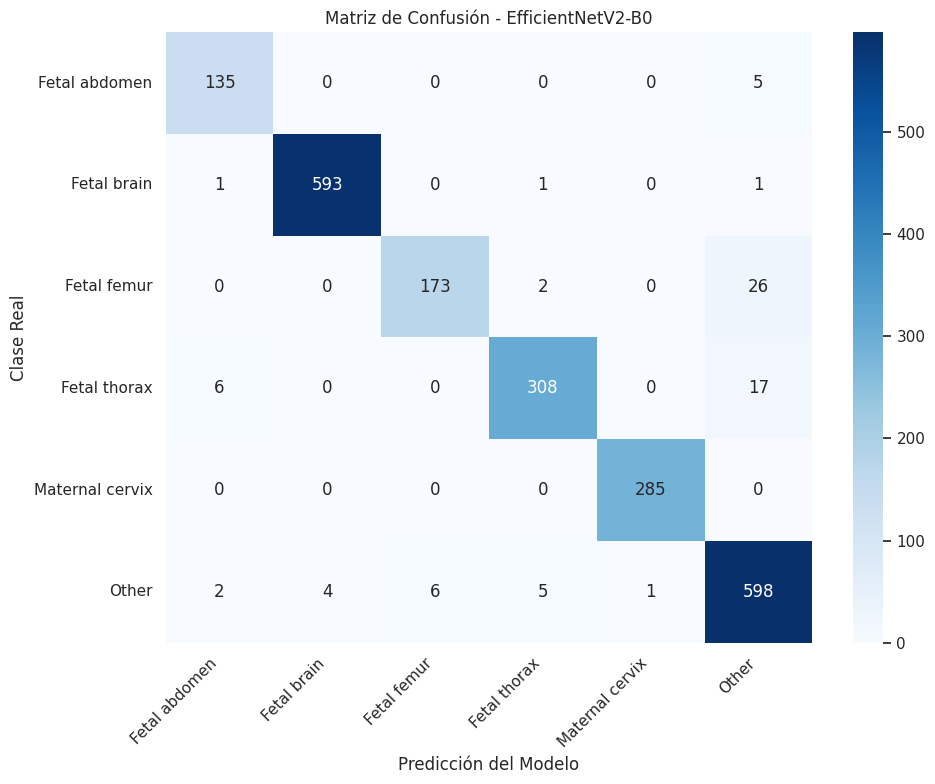

(sin curvas de pérdida guardadas para este modelo: solo existen si se entrenó con este notebook)


In [8]:
#@title EfficientNetV2-B0: matriz de confusión y curva de pérdida
plot_cm(pred_efnet, 'EfficientNetV2-B0', 'Blues', 'cm_efficientnet.png')
plot_loss(info_efnet, 'EfficientNetV2-B0', 'loss_efficientnet.png')

Casos XAI (índices de df_test): [2051, 1357, 1847]
EfficientNetV2-B0: capa conv usada = top_activation


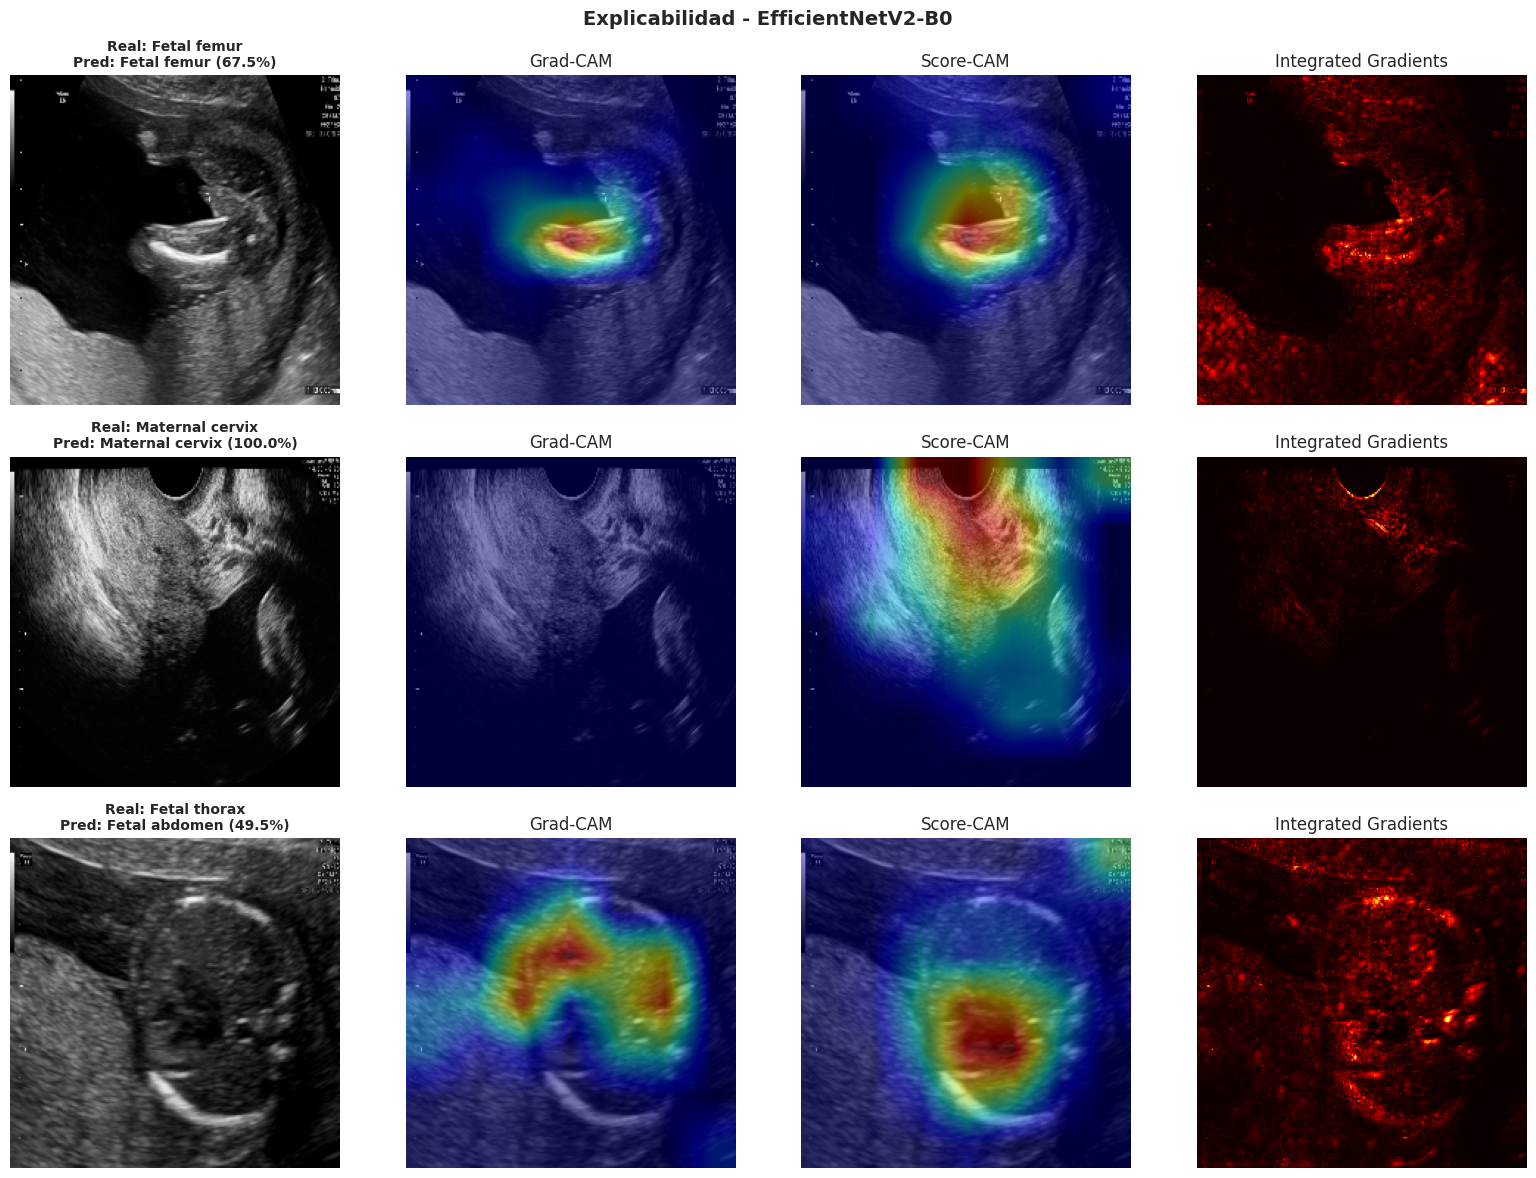

In [9]:
#@title EfficientNetV2-B0: explicabilidad (los mismos casos se usan para los 3 modelos)
XAI_IDX = pick_xai_samples(pred_efnet, n_ok=2, n_err=1, seed=7)
print('Casos XAI (índices de df_test):', XAI_IDX)
xai_cnn(model_EfNetB0, 'EfficientNetV2-B0', ['top_activation', 'top_conv'], XAI_IDX, 'xai_efficientnet.png')

## 8. Modelo 2: DenseNet-121

In [10]:
#@title 8. DenseNet-121: cargar (o entrenar) y evaluar
RETRAIN_DENSENET = False
model_DenseNet121, info_dn = get_or_train_cnn(
    'DenseNet121', DenseNet121, 'DenseNet121_PlanosFetales.keras',
    RETRAIN_DENSENET, ep_head=3, ep_fine=10)

pred_dn, rep_dn = evaluate_model(model_DenseNet121.predict(test_ds, verbose=0), 'DenseNet-121')
params_dn = model_DenseNet121.count_params()

Cargando DenseNet121 desde /content/drive/MyDrive/IA2/Proyecto/modelos/DenseNet121_PlanosFetales.keras
                 precision    recall  f1-score   support

  Fetal abdomen      0.931     0.771     0.844       140
    Fetal brain      0.992     0.987     0.989       596
    Fetal femur      0.950     0.856     0.901       201
   Fetal thorax      0.960     0.804     0.875       331
Maternal cervix      0.908     1.000     0.952       285
          Other      0.860     0.961     0.908       616

       accuracy                          0.927      2169
      macro avg      0.934     0.896     0.911      2169
   weighted avg      0.931     0.927     0.926      2169



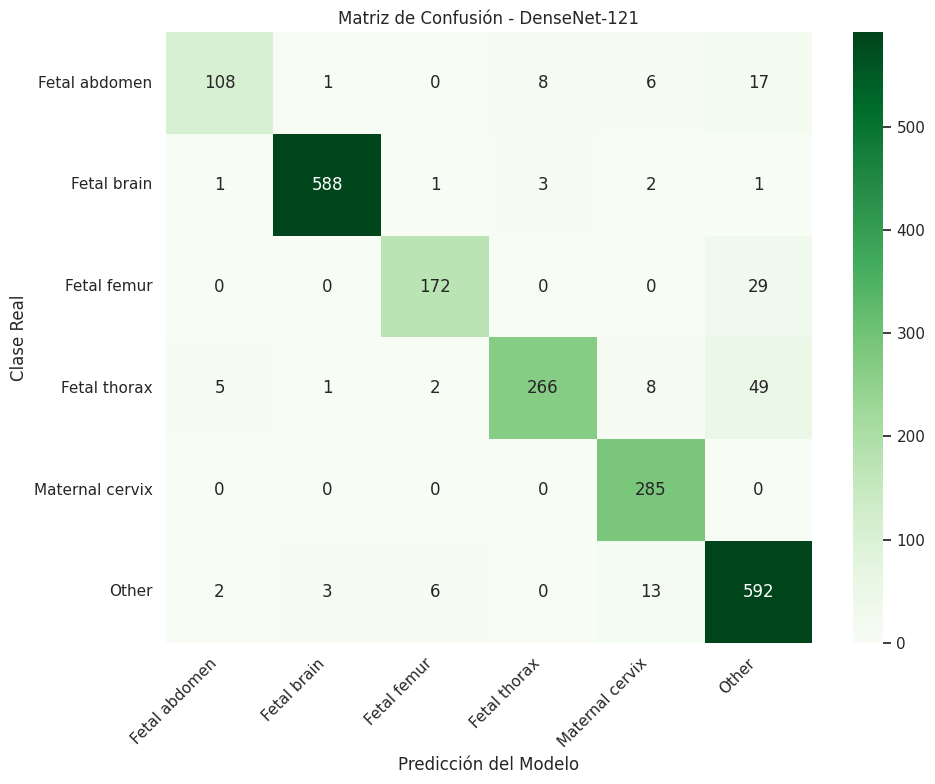

(sin curvas de pérdida guardadas para este modelo: solo existen si se entrenó con este notebook)


In [11]:
#@title DenseNet-121: matriz de confusión y curva de pérdida
plot_cm(pred_dn, 'DenseNet-121', 'Greens', 'cm_densenet.png')
plot_loss(info_dn, 'DenseNet-121', 'loss_densenet.png')

DenseNet-121: capa conv usada = relu


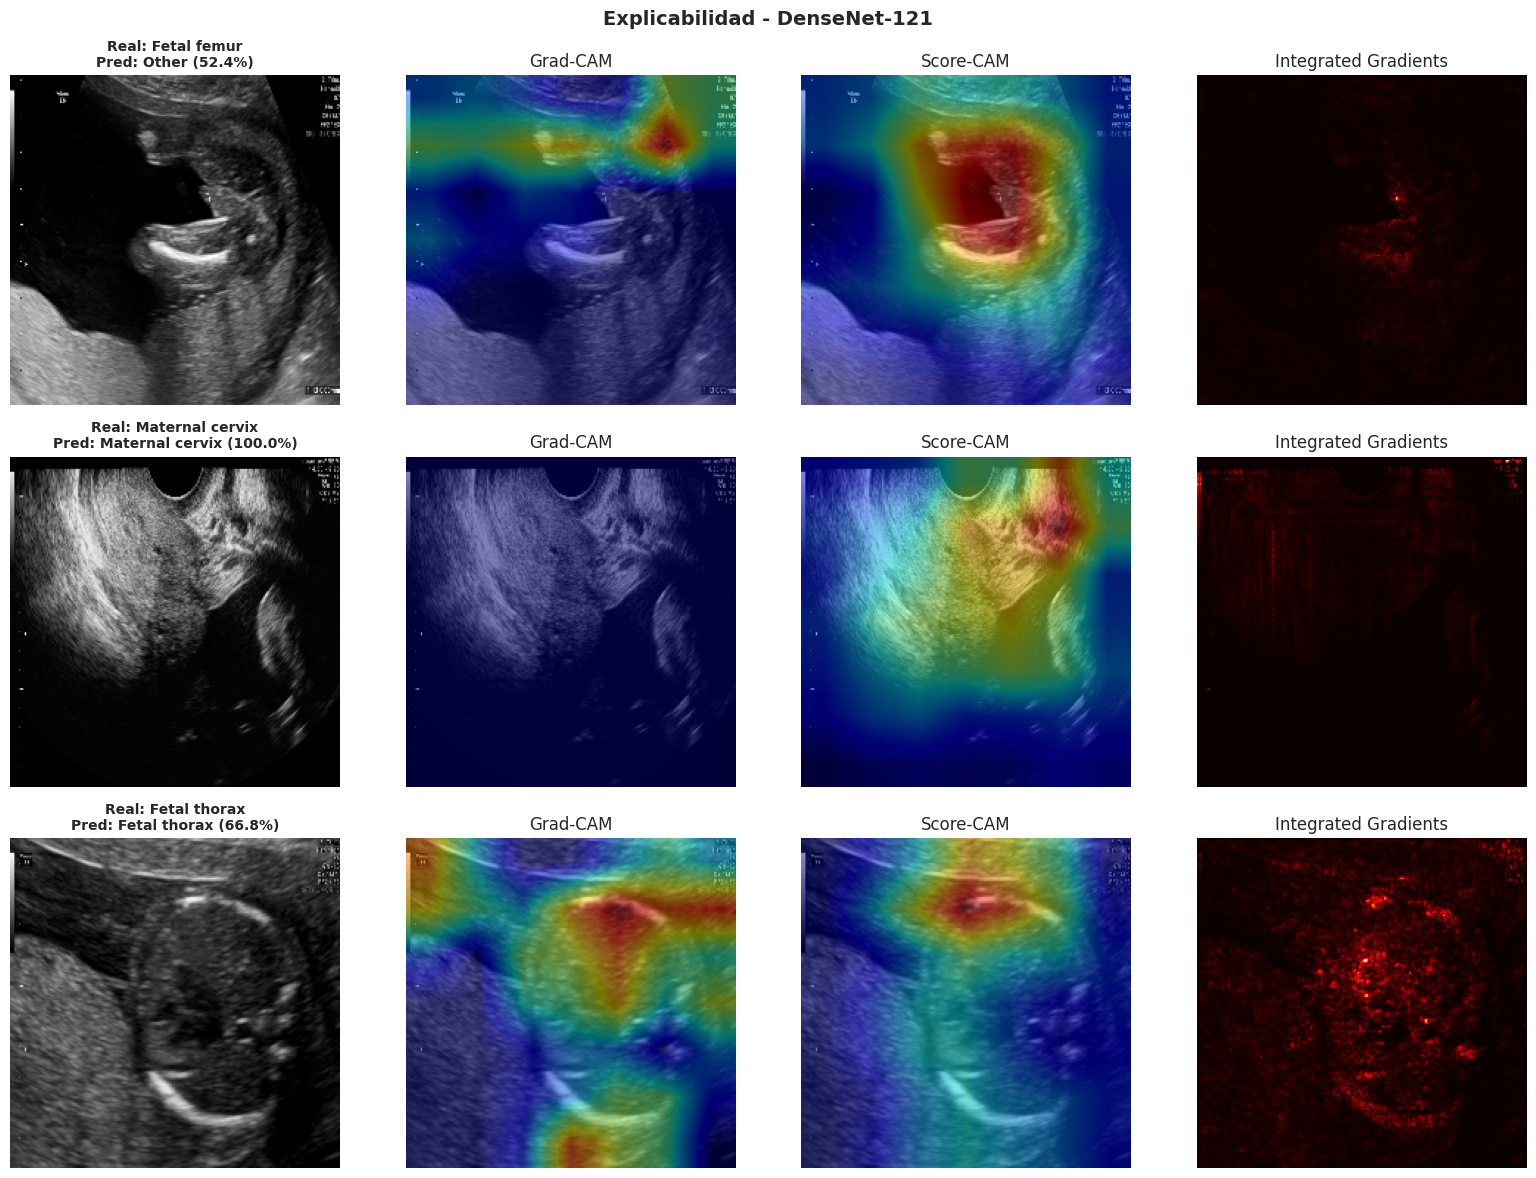

In [12]:
#@title DenseNet-121: explicabilidad (mismos casos que EfficientNet)
xai_cnn(model_DenseNet121, 'DenseNet-121', ['relu'], XAI_IDX, 'xai_densenet.png')

## 9. Modelo 3: Vision Transformer (ViT-B/16) — en PyTorch

> **Por qué PyTorch y no TensorFlow:** desde la versión 5, la librería `transformers` de Hugging Face dejó de dar soporte a TensorFlow (`TFViTModel` ya no existe), así que el ViT se entrena con PyTorch. Usa **exactamente los mismos datos** (`tr_df`, `va_df`, `df_test`), las mismas clases, los mismos aumentos (volteo, rotación ±30°, zoom 0.2, aplicados en GPU), el mismo esquema de 2 fases (cabeza → fine-tuning), el mismo Adam 1e-3 / 1e-5 y los mismos pesos de clase que las CNNs, así que la comparación es justa. Para explicabilidad se usa **Attention Rollout**, porque Grad-CAM necesita mapas convolucionales que el ViT no tiene.

In [13]:
#@title 9a. ViT: dependencias y definición del modelo
import torch, torch.nn as nn, torch.nn.functional as F
from concurrent.futures import ThreadPoolExecutor
from transformers import ViTModel

device  = 'cuda' if torch.cuda.is_available() else 'cpu'
USE_AMP = device == 'cuda'
VIT_CKPT = 'google/vit-base-patch16-224-in21k'
VIT_CONFIG_OVERRIDE = None        # solo para pruebas rápidas sin descargar pesos; dejar en None
torch.manual_seed(SEED)

def build_vit_backbone(attn='sdpa'):
    if VIT_CONFIG_OVERRIDE is not None:
        from transformers import ViTConfig
        cfg = ViTConfig(**VIT_CONFIG_OVERRIDE); cfg._attn_implementation = attn
        return ViTModel(cfg, add_pooling_layer=False)
    return ViTModel.from_pretrained(VIT_CKPT, add_pooling_layer=False, attn_implementation=attn)

class ViTClassifier(nn.Module):
    """ViT-B/16 preentrenado + misma cabeza que las CNNs (Dense 64 -> Dropout 0.1 -> salida)."""
    def __init__(self, n_classes, attn='sdpa'):
        super().__init__()
        self.vit = build_vit_backbone(attn)
        h = self.vit.config.hidden_size
        self.head = nn.Sequential(nn.Linear(h, 64), nn.ReLU(), nn.Dropout(0.1), nn.Linear(64, n_classes))
    def forward(self, x, output_attentions=False):
        out = self.vit(pixel_values=x, output_attentions=output_attentions)
        logits = self.head(out.last_hidden_state[:, 0])           # token [CLS]
        return (logits, out.attentions) if output_attentions else logits

def to_input(xb_uint8):
    return xb_uint8.to(device, non_blocking=True).permute(0, 3, 1, 2).float() / 255.0
def normalize(x):                                                  # ViT in21k espera [-1, 1]
    return (x - 0.5) / 0.5

def gpu_augment(x):
    """RandomFlip(h+v) + RandomRotation(±30°) + RandomZoom(0.2), por muestra y en GPU. x en [0,1]."""
    B, dev = x.size(0), x.device
    ang  = (torch.rand(B, device=dev) * 2 - 1) * math.radians(30)
    zoom = 1 + (torch.rand(B, device=dev) * 2 - 1) * 0.2
    fh = torch.where(torch.rand(B, device=dev) < 0.5, -1.0, 1.0)
    fv = torch.where(torch.rand(B, device=dev) < 0.5, -1.0, 1.0)
    cos, sin = torch.cos(ang) / zoom, torch.sin(ang) / zoom
    theta = torch.zeros(B, 2, 3, device=dev)
    theta[:, 0, 0] = cos * fh; theta[:, 0, 1] = -sin * fh
    theta[:, 1, 0] = sin * fv; theta[:, 1, 1] = cos * fv
    grid = F.affine_grid(theta, list(x.shape), align_corners=False)
    return F.grid_sample(x, grid, padding_mode='reflection', align_corners=False)

def load_many(paths, workers=8):
    def _one(p):
        img = cv2.imread(str(p))
        if img is None: raise FileNotFoundError(str(p))
        return cv2.resize(cv2.cvtColor(img, cv2.COLOR_BGR2RGB), (IMG_SIZE, IMG_SIZE))
    with ThreadPoolExecutor(workers) as ex:
        return np.stack(list(tqdm(ex.map(_one, list(paths)), total=len(paths))))

@torch.no_grad()
def predict_probs(model, X, bs=64):
    model.eval(); out = []
    for i in range(0, len(X), bs):
        xb = normalize(to_input(torch.from_numpy(X[i:i+bs])))
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=USE_AMP):
            out.append(torch.softmax(model(xb).float(), dim=-1).cpu())
    return torch.cat(out).numpy()

def run_phase(model, params, lr, epochs, Xtr, ytr, Xva, yva, class_w, bs, patience, tag):
    opt    = torch.optim.Adam(params, lr=lr)
    sched  = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.3, patience=1, min_lr=1e-7)
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
    crit   = nn.CrossEntropyLoss(weight=class_w)
    best, best_state, bad, hist = float('inf'), None, 0, {'loss': [], 'val_loss': []}
    for ep in range(epochs):
        model.train(); perm = np.random.permutation(len(Xtr)); tot, n = 0.0, 0
        for i in range(0, len(perm), bs):
            idx = np.sort(perm[i:i+bs])
            x = normalize(gpu_augment(to_input(torch.from_numpy(Xtr[idx])))); y = torch.from_numpy(ytr[idx]).to(device)
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=USE_AMP):
                loss = crit(model(x).float(), y)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot += loss.item() * len(idx); n += len(idx)
        probs = predict_probs(model, Xva)
        vloss = float(F.nll_loss(torch.log(torch.from_numpy(probs) + 1e-8), torch.from_numpy(yva)))
        vacc  = float((probs.argmax(1) == yva).mean())
        sched.step(vloss); hist['loss'].append(tot / n); hist['val_loss'].append(vloss)
        print(f'[{tag}] época {ep+1}/{epochs} | loss {tot/n:.4f} | val_loss {vloss:.4f} | val_acc {vacc:.4f}')
        if vloss < best - 1e-4:
            best, bad = vloss, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience: print(f'[{tag}] early stopping'); break
    if best_state is not None: model.load_state_dict(best_state)
    return hist
print('Dispositivo PyTorch:', device)

Dispositivo PyTorch: cuda


In [14]:
#@title 9b. ViT: cargar (o entrenar) y evaluar
RETRAIN_VIT   = False
EPOCHS_HEAD_VIT, EPOCHS_FINE_VIT = 3, 6      # si falta tiempo: baja EPOCHS_FINE_VIT (o ponlo en 0 y reporta solo la fase 1)
LR_HEAD_VIT, LR_FINE_VIT = 1e-3, 1e-5
BS_VIT = 32
VIT_FILE = 'ViT_PlanosFetales.pt'

# imágenes en RAM (uint8) para entrenar rápido sin releer Drive en cada época
Xte = load_many(df_test['filepath'])
yte = true_labels.astype('int64')
model_ViT = ViTClassifier(num_classes).to(device)
path_vit, meta = find_file(VIT_FILE), load_meta()

if path_vit is not None and not RETRAIN_VIT:
    print('Cargando ViT desde', path_vit)
    model_ViT.load_state_dict(torch.load(path_vit, map_location=device)); info_vit = meta.get('ViT', {})
else:
    print('Entrenando ViT ...')
    Xtr = load_many(tr_df['filepath']); ytr = tr_df['Plane'].map(class_to_idx).values.astype('int64')
    Xva = load_many(va_df['filepath']); yva = va_df['Plane'].map(class_to_idx).values.astype('int64')
    cw = torch.tensor([CLASS_WEIGHT[i] for i in range(num_classes)], dtype=torch.float32, device=device)
    t0 = time.time()
    for p in model_ViT.vit.parameters(): p.requires_grad = False          # Fase 1: solo la cabeza
    h1 = run_phase(model_ViT, model_ViT.head.parameters(), LR_HEAD_VIT, EPOCHS_HEAD_VIT, Xtr, ytr, Xva, yva, cw, BS_VIT, 2, 'ViT cabeza')
    h2 = {'loss': [], 'val_loss': []}
    if EPOCHS_FINE_VIT > 0:
        for p in model_ViT.vit.parameters(): p.requires_grad = True       # Fase 2: fine-tuning completo
        h2 = run_phase(model_ViT, model_ViT.parameters(), LR_FINE_VIT, EPOCHS_FINE_VIT, Xtr, ytr, Xva, yva, cw, BS_VIT, 3, 'ViT fine-tuning')
    secs = time.time() - t0
    print(f'Tiempo de entrenamiento ViT: {secs/60:.1f} min')
    torch.save(model_ViT.state_dict(), DATASET_DIR / VIT_FILE); print('Guardado en', DATASET_DIR / VIT_FILE)
    info_vit = {'train_time_s': secs, 'loss': h1['loss'] + h2['loss'], 'val_loss': h1['val_loss'] + h2['val_loss'], 'phase1_epochs': len(h1['loss'])}
    meta['ViT'] = info_vit; save_meta(meta)
    del Xtr, Xva

probs_vit = predict_probs(model_ViT, Xte)
pred_vit, rep_vit = evaluate_model(probs_vit, 'ViT-B/16')
params_vit = sum(p.numel() for p in model_ViT.parameters())

  0%|          | 0/2169 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTModel LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     |  | 
--------------------+------------+--+-
pooler.dense.bias   | UNEXPECTED |  | 
pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Entrenando ViT ...


  0%|          | 0/10391 [00:00<?, ?it/s]

  0%|          | 0/1682 [00:00<?, ?it/s]

[ViT cabeza] época 1/3 | loss 0.9471 | val_loss 0.6445 | val_acc 0.8335
[ViT cabeza] época 2/3 | loss 0.4965 | val_loss 0.4796 | val_acc 0.8567
[ViT cabeza] época 3/3 | loss 0.4057 | val_loss 0.4263 | val_acc 0.8805
[ViT fine-tuning] época 1/6 | loss 0.2199 | val_loss 0.1565 | val_acc 0.9489
[ViT fine-tuning] época 2/6 | loss 0.1123 | val_loss 0.1371 | val_acc 0.9536
[ViT fine-tuning] época 3/6 | loss 0.0827 | val_loss 0.1392 | val_acc 0.9566
[ViT fine-tuning] época 4/6 | loss 0.0647 | val_loss 0.1721 | val_acc 0.9483
[ViT fine-tuning] época 5/6 | loss 0.0498 | val_loss 0.1141 | val_acc 0.9655
[ViT fine-tuning] época 6/6 | loss 0.0400 | val_loss 0.1150 | val_acc 0.9631
Tiempo de entrenamiento ViT: 12.3 min
Guardado en /content/drive/MyDrive/IA2/Proyecto/dataset/ViT_PlanosFetales.pt
                 precision    recall  f1-score   support

  Fetal abdomen      0.938     0.979     0.958       140
    Fetal brain      0.992     0.995     0.993       596
    Fetal femur      0.944     0.92

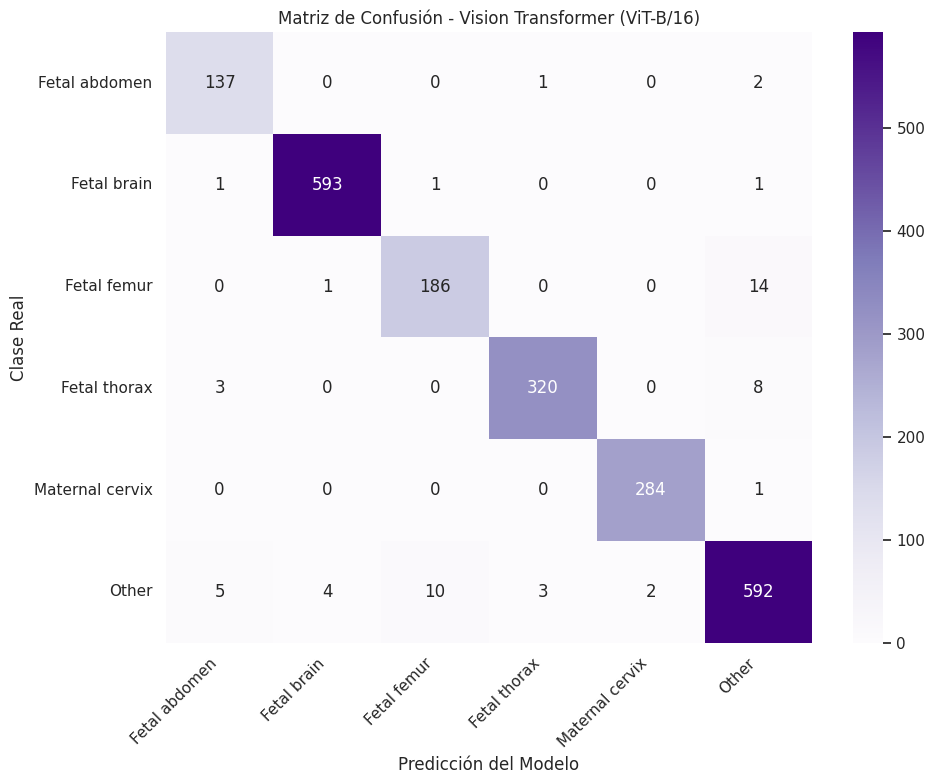

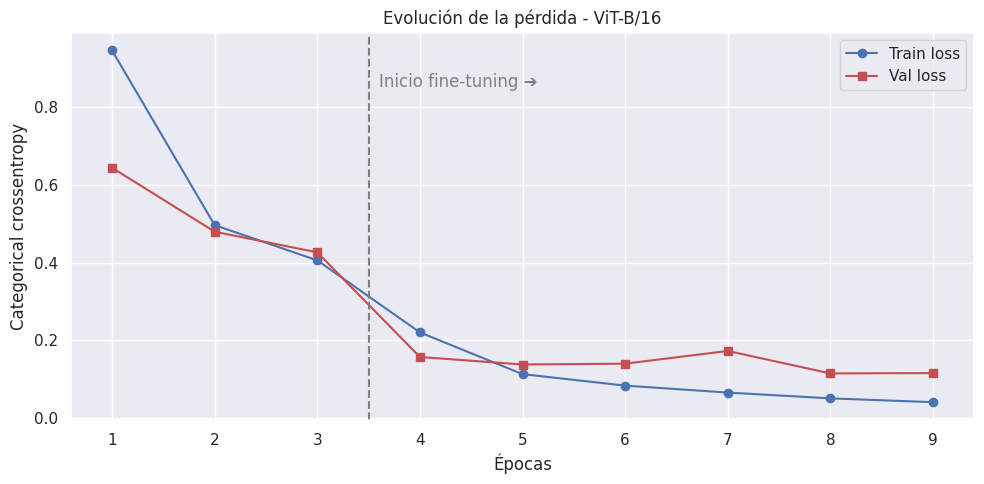

In [15]:
#@title ViT: matriz de confusión y curva de pérdida
plot_cm(pred_vit, 'Vision Transformer (ViT-B/16)', 'Purples', 'cm_vit.png')
plot_loss(info_vit, 'ViT-B/16', 'loss_vit.png')

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTModel LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     |  | 
--------------------+------------+--+-
pooler.dense.bias   | UNEXPECTED |  | 
pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


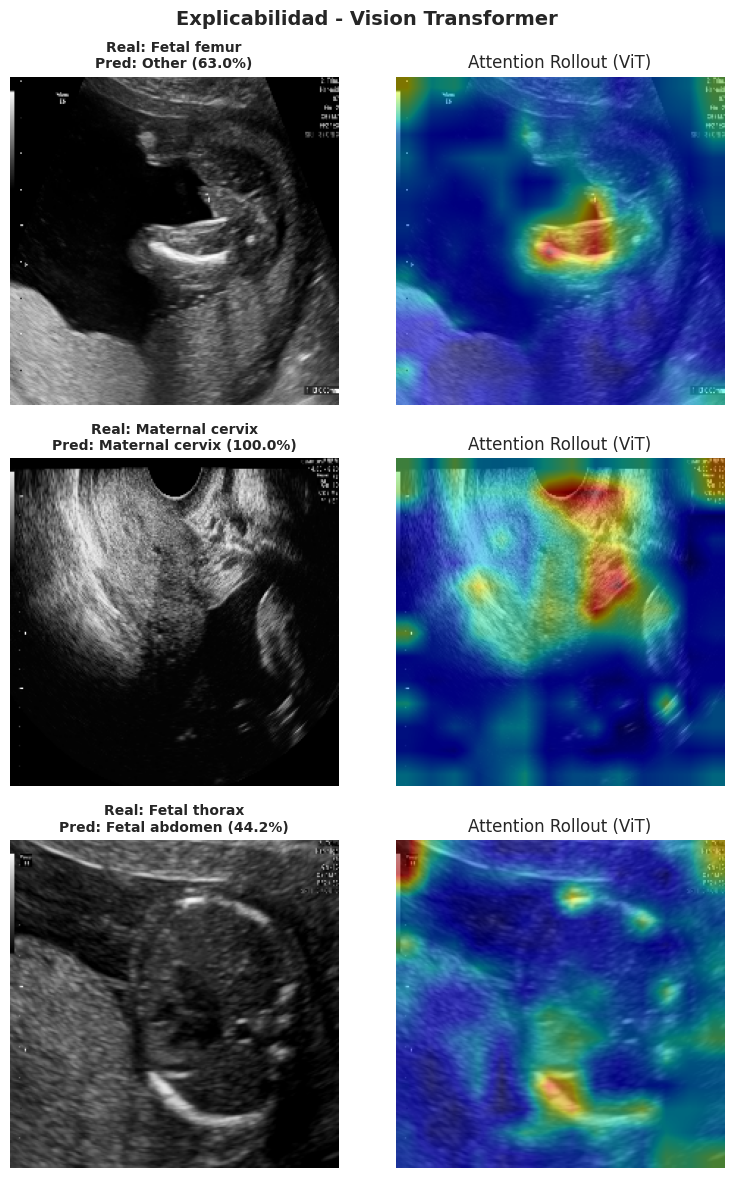

In [16]:
#@title ViT: explicabilidad con Attention Rollout (mismos casos que las CNNs)
# Rollout: se promedian las cabezas, se suma la identidad (conexión residual), se normaliza por filas y se encadenan las capas.
@torch.no_grad()
def attention_rollout(model_eager, img_uint8):
    model_eager.eval()
    x = normalize(to_input(torch.from_numpy(img_uint8[None])))
    logits, atts = model_eager(x, output_attentions=True)
    T = atts[0].shape[-1]; result = torch.eye(T, device=x.device)
    for a in atts:
        a = a[0].float().mean(0) + torch.eye(T, device=x.device)
        a = a / a.sum(-1, keepdim=True); result = a @ result
    cls = result[0, 1:].cpu().numpy(); g = int(round(math.sqrt(cls.shape[0])))
    cls = cls.reshape(g, g); cls = cls / (cls.max() + 1e-8)
    return cls, torch.softmax(logits.float(), -1)[0].cpu().numpy()

# la atención explícita solo está disponible con la implementación "eager": se copia el modelo entrenado a una instancia eager
model_ViT_eager = ViTClassifier(num_classes, attn='eager').to(device)
model_ViT_eager.load_state_dict(model_ViT.state_dict())

fig, axes = plt.subplots(len(XAI_IDX), 2, figsize=(8, 4 * len(XAI_IDX)), squeeze=False)
for r, i in enumerate(XAI_IDX):
    row = df_test.iloc[i]; rgb = read_rgb(row['filepath'])
    cam, probs = attention_rollout(model_ViT_eager, rgb); p = int(np.argmax(probs))
    axes[r, 0].imshow(rgb); axes[r, 0].set_title(f"Real: {row['Plane']}\nPred: {classes[p]} ({probs[p]*100:.1f}%)", fontsize=10, fontweight='bold')
    axes[r, 1].imshow(rgb); axes[r, 1].imshow(cv2.resize(cam, (IMG_SIZE, IMG_SIZE)), cmap='jet', alpha=0.5); axes[r, 1].set_title('Attention Rollout (ViT)')
    for a in axes[r]: a.axis('off')
plt.suptitle('Explicabilidad - Vision Transformer', fontsize=14, fontweight='bold'); plt.tight_layout()
plt.savefig(FIGS_DIR / 'xai_vit.png', dpi=150); plt.show()
del model_ViT_eager

## 10. Benchmark comparativo final

,Modelo,Accuracy,F1 macro,F1 ponderado,Parámetros,Entrenamiento (min)
0,EfficientNetV2-B0,0.9645,0.9588,0.9643,"6,001,686",NaN
1,DenseNet-121,0.9272,0.9113,0.9261,"7,103,494",NaN
2,ViT-B/16,0.9737,0.9696,0.9737,"85,848,262",12.3


,EfficientNetV2-B0,DenseNet-121,ViT-B/16
Fetal abdomen,0.951,0.844,0.958
Fetal brain,0.994,0.989,0.993
Fetal femur,0.911,0.901,0.935
Fetal thorax,0.952,0.875,0.977
Maternal cervix,0.998,0.952,0.995
Other,0.947,0.908,0.959


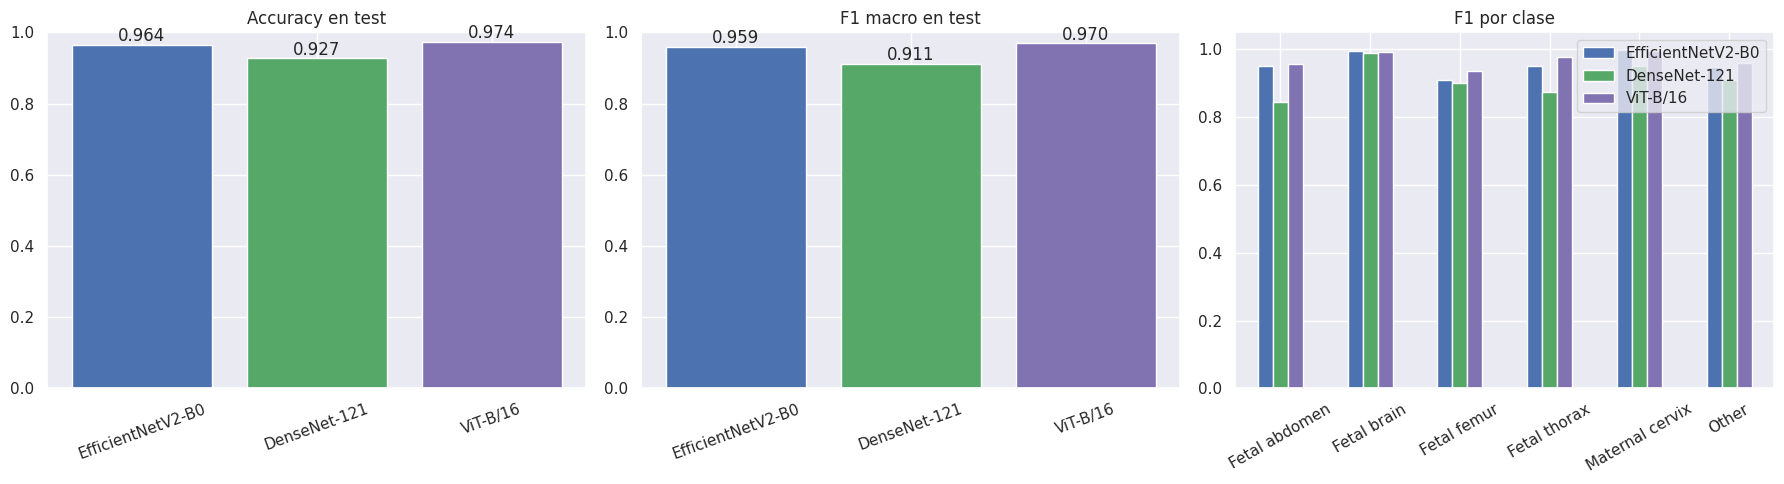

Figuras guardadas en /content/drive/MyDrive/IA2/Proyecto/dataset/figuras


In [17]:
#@title 10. Tabla comparativa y gráficas para las diapositivas
meta = load_meta()
def _min(tag):
    t = meta.get(tag, {}).get('train_time_s'); return None if t is None else round(t / 60, 1)

filas = []
for nombre, rep, params, tag in [('EfficientNetV2-B0', rep_efnet, params_efnet, 'EfficientNetV2B0'),
                                 ('DenseNet-121',      rep_dn,    params_dn,    'DenseNet121'),
                                 ('ViT-B/16',          rep_vit,   params_vit,   'ViT')]:
    filas.append({'Modelo': nombre, 'Accuracy': rep['accuracy'], 'F1 macro': rep['macro avg']['f1-score'],
                  'F1 ponderado': rep['weighted avg']['f1-score'], 'Parámetros': params, 'Entrenamiento (min)': _min(tag)})
benchmark_df = pd.DataFrame(filas)
disp = benchmark_df.copy(); disp['Parámetros'] = disp['Parámetros'].map(lambda p: f'{p:,}')
display(disp.round(4))
benchmark_df.to_csv(DATASET_DIR / 'benchmark_modelos.csv', index=False)

# F1 por clase (para la discusión de resultados)
f1_clase = pd.DataFrame({n: [rep[c]['f1-score'] for c in classes] for n, rep in
                         [('EfficientNetV2-B0', rep_efnet), ('DenseNet-121', rep_dn), ('ViT-B/16', rep_vit)]}, index=classes)
display(f1_clase.round(3)); f1_clase.to_csv(DATASET_DIR / 'benchmark_f1_por_clase.csv')

fig, ax = plt.subplots(1, 3, figsize=(18, 5)); cols = ['#4C72B0', '#55A868', '#8172B2']
for a, m_ in zip(ax[:2], ['Accuracy', 'F1 macro']):
    a.bar(benchmark_df['Modelo'], benchmark_df[m_], color=cols); a.set_ylim(0, 1); a.set_title(f'{m_} en test'); a.tick_params(axis='x', rotation=20)
    for x_, v in enumerate(benchmark_df[m_]): a.text(x_, v + 0.01, f'{v:.3f}', ha='center')
f1_clase.plot.bar(ax=ax[2], color=cols); ax[2].set_ylim(0, 1.05); ax[2].set_title('F1 por clase'); ax[2].tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.savefig(FIGS_DIR / 'benchmark.png', dpi=150); plt.show()
print('Figuras guardadas en', FIGS_DIR)

## Notas para la presentación (limitaciones honestas)

- **Los 3 modelos se comparan con el mismo split, los mismos datos, los mismos aumentos y el mismo esquema de 2 fases.** Es una corrida por modelo (una semilla): diferencias de 1–2 puntos no son concluyentes.
- **Split por imagen, no por paciente en train/test.** El split train/test viene del notebook de preparación (80/20 estratificado por imagen). La celda 3 imprime cuántos pacientes de test también están en train; si es alto, el rendimiento puede estar algo inflado respecto a un hospital nuevo. En esta versión la validación sí se separa por paciente.
- **DenseNet-121 se alimenta con píxeles 0–255 sin `preprocess_input`** (EfficientNetV2 ya lo incluye internamente). Eso puede restarle algo de rendimiento frente a EfficientNet; no se cambió para no invalidar el modelo ya entrenado.
- **La clase `Other` concentra la mayoría de los errores** (p. ej. fémur→Other, tórax→Other): son vistas no estándar o ambiguas. Conviene mostrar 6–8 de esos casos.
- **XAI:** Grad-CAM, Score-CAM e Integrated Gradients para las CNNs; Attention Rollout para el ViT. Son mapas cualitativos: no demuestran por sí solos que el modelo "razona" como un clínico.
- **Si el ViT queda por debajo de las CNNs** es esperable con ~13 mil imágenes (los ViT necesitan más datos o más épocas); es un resultado reportable, no un error.